# Qiskit Fall Fest 2026
## Challenge 4: Correlated and Opposite Outcomes

**Objective:** Design two two-qubit quantum circuits that produce correlated and opposite measurement outcomes, then compare their results using histograms.

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()

## Theory and Predictions

A Bell-state circuit uses a Hadamard (H) gate followed by a CNOT gate to create an entangled state.

### Part A: Correlated outcomes
The circuit produces matching measurement results:
- 00: approximately 50%
- 11: approximately 50%

### Part B: Opposite outcomes
Adding an X gate to qubit 0 flips that qubit:
- 01: approximately 50%
- 10: approximately 50%

The predictions assume ideal quantum simulation. The actual counts may vary slightly because each circuit is executed for 100 shots.


Part A: Correlated Outcomes


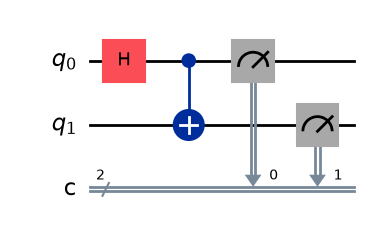

Part A measurement results: {'00': 49, '11': 51}


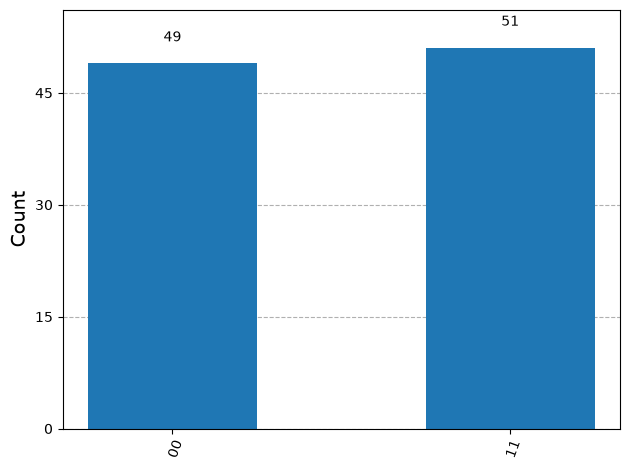

In [5]:
circuit_a = QuantumCircuit(2, 2)

circuit_a.h(0)
circuit_a.cx(0, 1)

circuit_a.measure(0, 0)
circuit_a.measure(1, 1)

print("Part A: Correlated Outcomes")
display(circuit_a.draw("mpl"))

result_a = simulator.run(circuit_a, shots=100).result()
counts_a = result_a.get_counts()

print("Part A measurement results:", counts_a)

fig = plot_histogram(counts_a)
display(fig)
plt.close(fig)


Part B: Opposite Outcomes


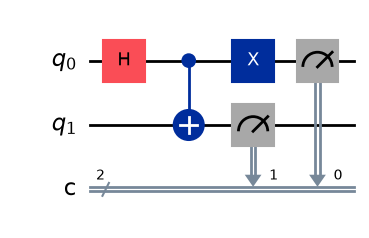

Part B measurement results: {'01': 53, '10': 47}


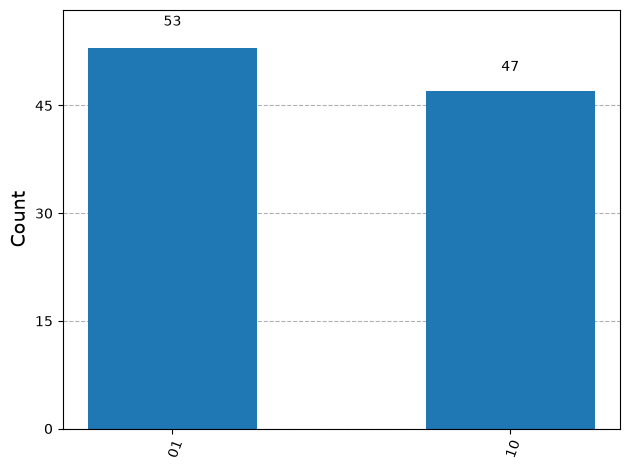

In [6]:
circuit_b = QuantumCircuit(2, 2)

circuit_b.h(0)
circuit_b.cx(0, 1)
circuit_b.x(0)

circuit_b.measure(0, 0)
circuit_b.measure(1, 1)

print("Part B: Opposite Outcomes")
display(circuit_b.draw("mpl"))

result_b = simulator.run(circuit_b, shots=100).result()
counts_b = result_b.get_counts()

print("Part B measurement results:", counts_b)

fig = plot_histogram(counts_b)
display(fig)
plt.close(fig)

Part A: Correlated outcomes
{'00': 49, '11': 51}

Part B: Opposite outcomes
{'01': 53, '10': 47}


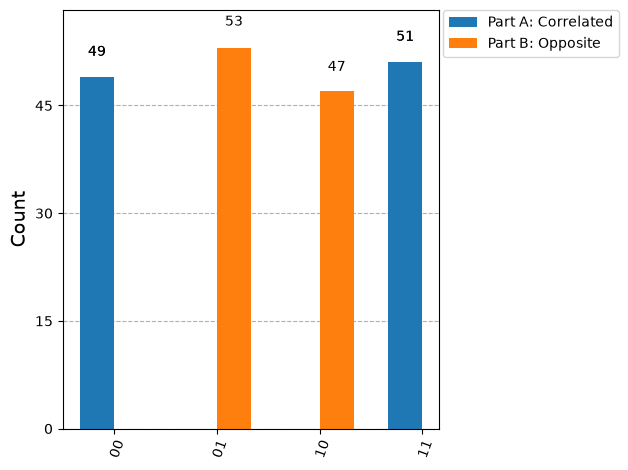

In [7]:
print("Part A: Correlated outcomes")
print(counts_a)

print("\nPart B: Opposite outcomes")
print(counts_b)

fig = plot_histogram(
    [counts_a, counts_b],
    legend=["Part A: Correlated", "Part B: Opposite"]
)

display(fig)
plt.close(fig)


## Comparison and Observations

### Part A
The dominant outcomes are 00 and 11. Both qubits produce the same measurement result.

### Part B
The dominant outcomes are 01 and 10. The qubits produce opposite measurement results.

### What changed?
I added one X gate to qubit 0 after the CNOT gate. This flips the state of that qubit and changes the measurement relationship.

### Will all four outcomes appear?
In an ideal simulation, Part A produces only 00 and 11, while Part B produces only 01 and 10. The other outcomes have zero probability in these circuits. Small deviations may occur on real quantum hardware due to noise.